# GARBAGE CLASSIFICATION — Object Detection EDA
**Independent Google Colab notebook** · No training required.

Investigates extreme differences in BIODEGRADABLE, GLASS, PAPER and PLASTIC across train/valid/test. Includes missing labels, invalid YOLO annotations, duplicate images, image sizes, object counts, class heatmaps, organic test examples, and a final audit report. **Run all cells in order.**

## 1 · Connect Google Drive and locate dataset

In [ ]:
%pip -q install pandas numpy matplotlib seaborn pillow pyyaml tqdm
# from kaggle directly next.

## 2 · Resolve class names and split folders





In [ ]:

# download the dataset from Kaggle, as published

import kagglehub, yaml, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from google.colab import drive

drive.mount('/content/drive')

dl = Path(kagglehub.dataset_download('viswaprakash1990/garbage-detection'))
SRC = sorted(dl.rglob('data.yaml'))[0].parent
print('Dataset:', SRC)
print('Contents:', sorted(p.name for p in SRC.iterdir()))

names = yaml.safe_load(open(SRC / 'data.yaml'))['names']
NAMES = {int(k): str(v) for k, v in names.items()} if isinstance(names, dict) else dict(enumerate(names))
C = [NAMES[k] for k in sorted(NAMES)]
print('Classes:', NAMES)

OUTPUT = Path('/content/drive/MyDrive/garbage_outputs')
OUTPUT.mkdir(parents=True, exist_ok=True)

for s in ['train', 'valid', 'test']:
    print(f'{s:5s}', len(list((SRC / s / 'images').iterdir())), 'images')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'garbage-detection' dataset.
Dataset: /kaggle/input/garbage-detection/GARBAGE CLASSIFICATION
Contents: ['data.yaml', 'test', 'train', 'valid']
Classes: {0: 'BIODEGRADABLE', 1: 'CARDBOARD', 2: 'GLASS', 3: 'METAL', 4: 'PAPER', 5: 'PLASTIC'}
train 7324 images
valid 2098 images
test  1042 images


## 3 · Scan every image and annotation (including missing/invalid labels)

In [ ]:
RAW_SPLITS = {'train': SRC / 'train' / 'images',
              'val':   SRC / 'valid' / 'images',
              'test':  SRC / 'test'  / 'images'}
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def audit(split_dirs, label):
    issues, n_img, n_box = [], 0, 0
    for split, img_dir in split_dirs.items():
        paths = sorted(p for p in img_dir.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        print(f'Scanning {split}: {len(paths)} images')
        for ip in tqdm(paths, desc=split):
            n_img += 1
            lp = ip.parent.parent / 'labels' / (ip.stem + '.txt')
            if not lp.exists():
                issues.append({'split': split, 'file': ip.stem, 'line': None,
                               'issue': 'missing label file', 'class': None, 'w': None, 'h': None,
                               'boxes_in_file': 0})
                continue
            lines = lp.read_text().splitlines()
            for i, line in enumerate(lines, 1):
                q = line.split()
                if not q: continue
                if len(q) != 5:
                    issues.append({'split': split, 'file': ip.stem, 'line': i, 'issue': 'malformed line',
                                   'class': None, 'w': None, 'h': None, 'boxes_in_file': len(lines)})
                    continue
                c = int(q[0]); x, y, w, h = map(float, q[1:])
                if not all(0 <= v <= 1 for v in (x, y, w, h)):
                    issues.append({'split': split, 'file': ip.stem, 'line': i,
                                   'issue': 'coordinate outside [0,1]', 'class': NAMES[c],
                                   'w': w, 'h': h, 'boxes_in_file': len(lines)})
                elif w == 0 or h == 0:
                    issues.append({'split': split, 'file': ip.stem, 'line': i, 'issue': 'zero-area box',
                                   'class': NAMES[c], 'w': w, 'h': h, 'boxes_in_file': len(lines)})
                else:
                    n_box += 1
    df = pd.DataFrame(issues)
    print(f'\n[{label}] Images: {n_img} | Valid boxes: {n_box} | Issues: {len(df)}')
    return df

bad = audit(RAW_SPLITS, 'RAW')
if len(bad):
    print('\nBy issue type:');       display(bad['issue'].value_counts().rename('count').to_frame())
    print('By split:');              display(bad['split'].value_counts().reindex(['train','val','test']).rename('count').to_frame())
    print('By class:');              display(pd.crosstab(bad['class'], bad['split']).reindex(columns=['train','val','test'], fill_value=0))
    print('\nEvery invalid annotation:'); display(bad)
    bad.to_csv(OUTPUT / 'invalid_annotations_raw.csv', index=False)

Scanning train: 7324 images


train:   0%|          | 0/7324 [00:00<?, ?it/s]

Scanning val: 2098 images


val:   0%|          | 0/2098 [00:00<?, ?it/s]

Scanning test: 1042 images


...

,count
split,
train,10
val,6
test,1


By class:


split,train,val,test
class,,,
BIODEGRADABLE,7,5,0
CARDBOARD,1,1,0
PAPER,2,0,1



Every invalid annotation:


,split,file,line,issue,class,w,h,boxes_in_file
0,train,biodegradable1465_jpg.rf.6554b314de4df3aed0117...,54,zero-area box,BIODEGRADABLE,0.012019,0.000000,64
1,train,biodegradable1740_jpg.rf.5f00e1157464c17341765...,64,zero-area box,BIODEGRADABLE,0.000000,0.043269,99
2,train,biodegradable1998_jpeg.rf.17921ee65cee3e00f10a...,261,zero-area box,BIODEGRADABLE,0.062500,0.000000,321
3,train,biodegradable2012_jpeg.rf.f157a4549b3da5de53b7...,26,zero-area box,BIODEGRADABLE,0.004808,0.000000,44
4,train,biodegradable366_jpg.rf.09e6cd29dee38feb3b4df8...,18,zero-area box,BIODEGRADABLE,0.048077,0.000000,92
5,train,biodegradable419_jpg.rf.3cb6ccbe84af9a0d1a0832...,32,zero-area box,BIODEGRADABLE,0.004808,0.000000,67
6,train,biodegradable421_jpg.rf.0d8bc76989848c2d9173e3...,94,zero-area box,BIODEGRADABLE,0.000000,0.007212,228
7,train,cardboard895_jpg.rf.9fe0d5e9a4d71705fa33323a01...,3,zero-area box,CARDBOARD,0.000000,0.004808,18
8,train,paper1805_jpeg.rf.3cbe8e415d51c085ff0165a12cea...,1,zero-area box,PAPER,0.000000,0.004808,3
9,train,paper787_jpg.rf.a776cf355b31868a4cfda6ff51850600,1,zero-area box,PAPER,0.004808,0.000000,2


## 4 · Split sizes, class distributions and imbalance

Images by split:


,images,unreadable,missing_labels,empty_or_invalid
split,,,,
train,7324,0,0,0
val,2098,0,0,0
test,1042,0,0,0


OBJECTS (bounding boxes) per class:


split,train,val,test
class_name,,,
BIODEGRADABLE,31714,13632,49
CARDBOARD,3385,1291,20
GLASS,5429,2380,0
METAL,3948,1360,533
PAPER,2979,33,1375
PLASTIC,4146,214,1585


IMAGES containing each class (image can appear in multiple rows):


split,train,val,test
class_name,,,
BIODEGRADABLE,1603,676,8
CARDBOARD,1053,438,11
GLASS,1879,805,0
METAL,1328,398,172
PAPER,1238,15,515
PLASTIC,1019,91,354


Class percentage by split:


split,train,val,test
class_name,,,
BIODEGRADABLE,61.46,72.09,1.38
CARDBOARD,6.56,6.83,0.56
GLASS,10.52,12.59,0.00
METAL,7.65,7.19,14.96
PAPER,5.77,0.17,38.60
PLASTIC,8.03,1.13,44.50


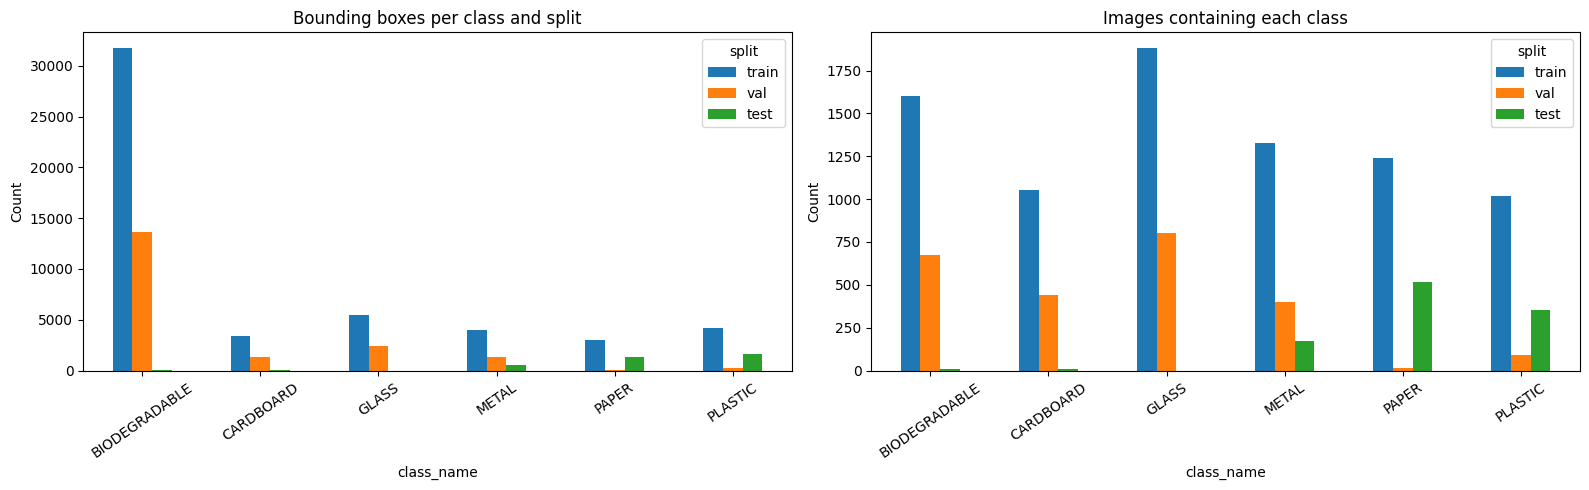

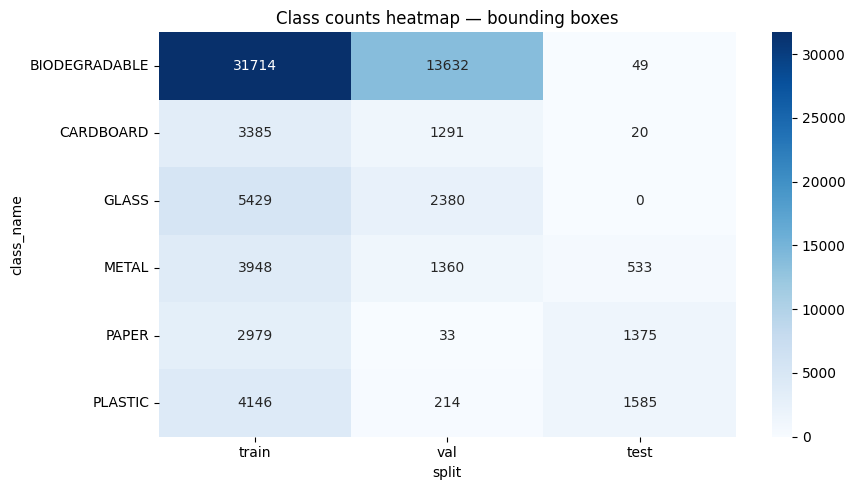

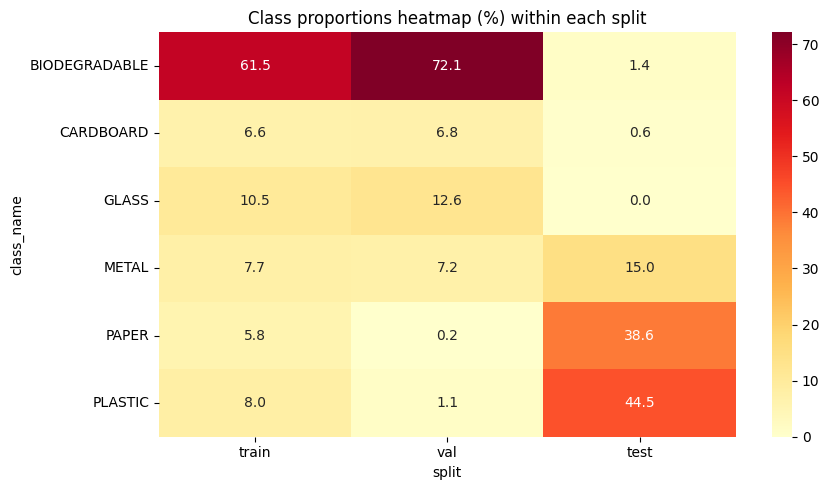

In [ ]:
import seaborn as sns
split_order=['train','val','test']
counts=boxes_df.groupby(['class_name','split']).size().unstack(fill_value=0).reindex(columns=split_order,fill_value=0).reindex(NAMES.values(),fill_value=0)
image_counts=(boxes_df.groupby(['class_name','split'])['image'].nunique().unstack(fill_value=0).reindex(columns=split_order,fill_value=0).reindex(NAMES.values(),fill_value=0))
print('Images by split:'); display(images_df.groupby('split').agg(images=('image','size'), unreadable=('image_ok',lambda s:(~s).sum()), missing_labels=('label_exists',lambda s:(~s).sum()), empty_or_invalid=('n_valid_objects',lambda s:(s==0).sum())).reindex(split_order))
print('OBJECTS (bounding boxes) per class:'); display(counts)
print('IMAGES containing each class (image can appear in multiple rows):'); display(image_counts)
print('Class percentage by split:'); display((counts.div(counts.sum(axis=0),axis=1)*100).round(2))
counts.to_csv(OUTPUT/'class_box_distribution.csv')
image_counts.to_csv(OUTPUT/'class_image_distribution.csv')
fig,axes=plt.subplots(1,2,figsize=(16,5))
counts.plot(kind='bar',ax=axes[0],title='Bounding boxes per class and split')
image_counts.plot(kind='bar',ax=axes[1],title='Images containing each class')
for ax in axes: ax.set_ylabel('Count');ax.tick_params(axis='x',rotation=35)
plt.tight_layout();plt.savefig(OUTPUT/'class_distributions.png',dpi=160);plt.show()

plt.figure(figsize=(9,5))
sns.heatmap(counts,annot=True,fmt='d',cmap='Blues')
plt.title('Class counts heatmap — bounding boxes');plt.tight_layout();plt.savefig(OUTPUT/'class_heatmap.png',dpi=160);plt.show()
plt.figure(figsize=(9,5))
sns.heatmap(counts.div(counts.sum(axis=0).replace(0,np.nan),axis=1)*100,annot=True,fmt='.1f',cmap='YlOrRd')
plt.title('Class proportions heatmap (%) within each split');plt.tight_layout();plt.savefig(OUTPUT/'class_percent_heatmap.png',dpi=160);plt.show()


## 5 · Image size, object count, and bounding box size

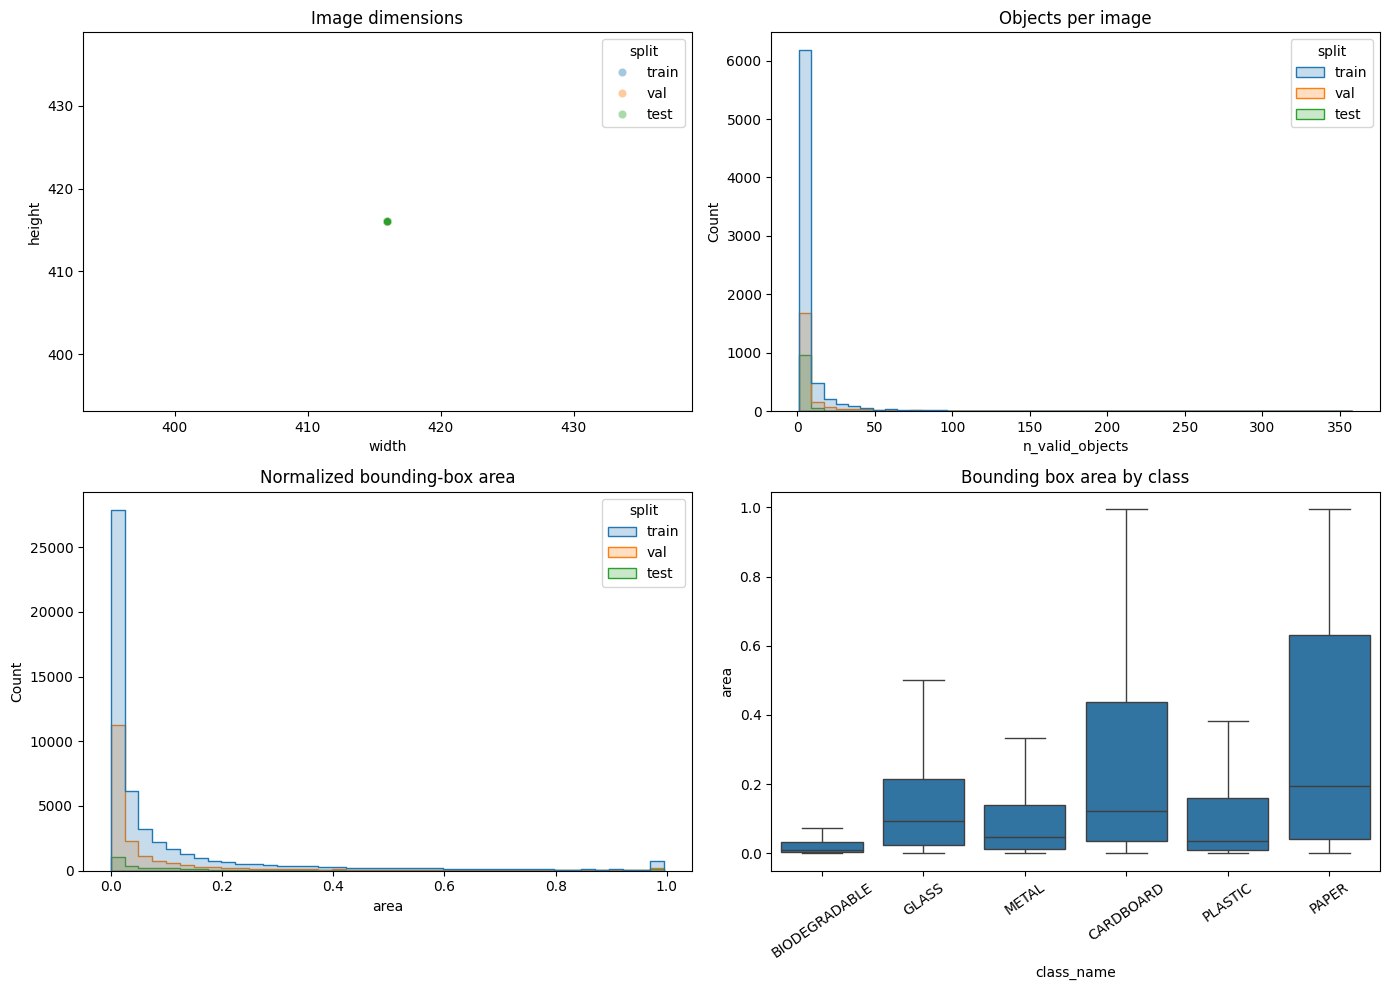

Image dimensions summary:


width                                                 height         \
        count   mean  std    min    25%    50%    75%    max   count   mean   
split                                                                         
test   1042.0  416.0  0.0  416.0  416.0  416.0  416.0  416.0  1042.0  416.0   
train  7324.0  416.0  0.0  416.0  416.0  416.0  416.0  416.0  7324.0  416.0   
val    2098.0  416.0  0.0  416.0  416.0  416.0  416.0  416.0  2098.0  416.0   

       ...               n_valid_objects                                        
       ...    75%    max           count mean   std  min  25%  50%  75%    max  
split  ...                                                                      
test   ...  416.0  416.0          1042.0  3.4   8.4  1.0  1.0  1.0  3.0  119.0  
train  ...  416.0  416.0          7324.0  7.0  19.3  1.0  1.0  2.0  5.0  358.0  
val    ...  416.0  416.0          2098.0  9.0  21.7  1.0  1.0  2.0  6.0  311.0  

[3 rows x 24 columns]

In [ ]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
sns.scatterplot(data=images_df,x='width',y='height',hue='split',alpha=.4,ax=axes[0,0]);axes[0,0].set_title('Image dimensions')
sns.histplot(data=images_df,x='n_valid_objects',hue='split',bins=45,element='step',ax=axes[0,1]);axes[0,1].set_title('Objects per image')
if not boxes_df.empty:
    sns.histplot(data=boxes_df,x='area',hue='split',bins=40,element='step',ax=axes[1,0]);axes[1,0].set_title('Normalized bounding-box area')
    sns.boxplot(data=boxes_df,x='class_name',y='area',ax=axes[1,1],showfliers=False);axes[1,1].tick_params(axis='x',rotation=35);axes[1,1].set_title('Bounding box area by class')
plt.tight_layout();plt.savefig(OUTPUT/'image_and_box_distributions.png',dpi=160);plt.show()
print('Image dimensions summary:');display(images_df.groupby('split')[['width','height','n_valid_objects']].describe().round(1))


1. Dataset size and splits

10,464 images: train 7,324, valid 2,098, test 1,042.
All images are a uniform 416×416 px, so there are no size outliers.

2. Annotation quality

17 invalid annotations were found, one per image, in 17 images (train 10, valid 6, test.

Action: the 17 lines were removed rather than clipped, since a zero-area box carries no recoverable information.
The removal did not leave any image empty, because every image still has at least 1 valid box.
Why it matters: the invalid PAPER box in test could never be matched by any model, so it would have counted as a missed detection and unfairly lowered PAPER recall and mAP.

3. split

Test scenes are noticeably sparser than validation scenes (mean 3.4 vs 9.0 objects per image; 75th percentile 3 vs 6).
The splits are therefore not identically distributed, which partly explains gaps between validation and test results.

## 6 · Organic bounding box location heatmap and co-occurrence

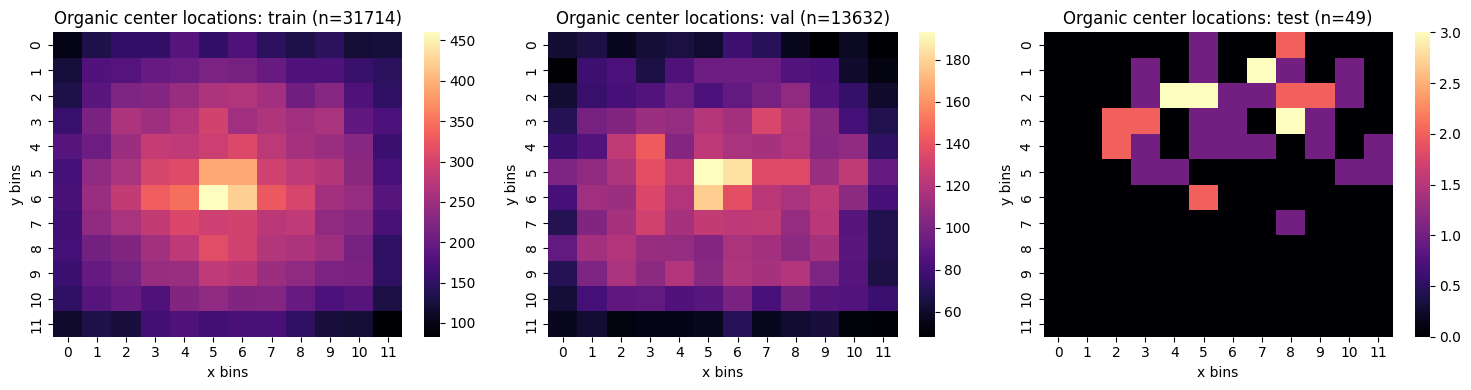

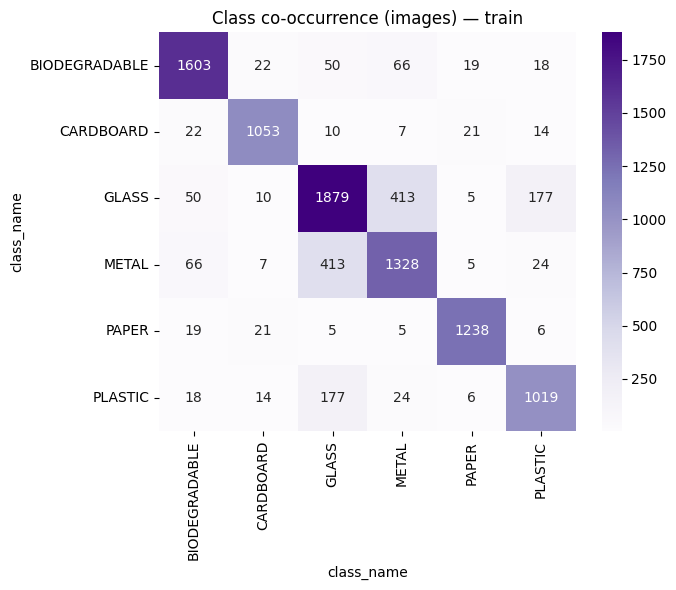

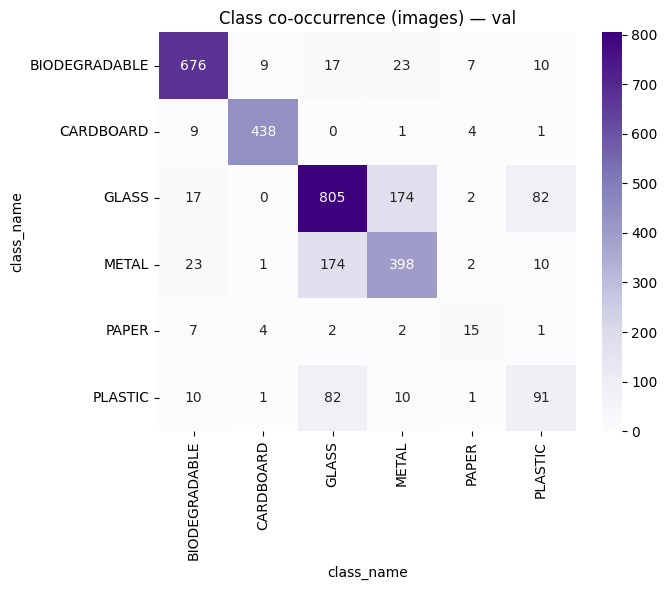

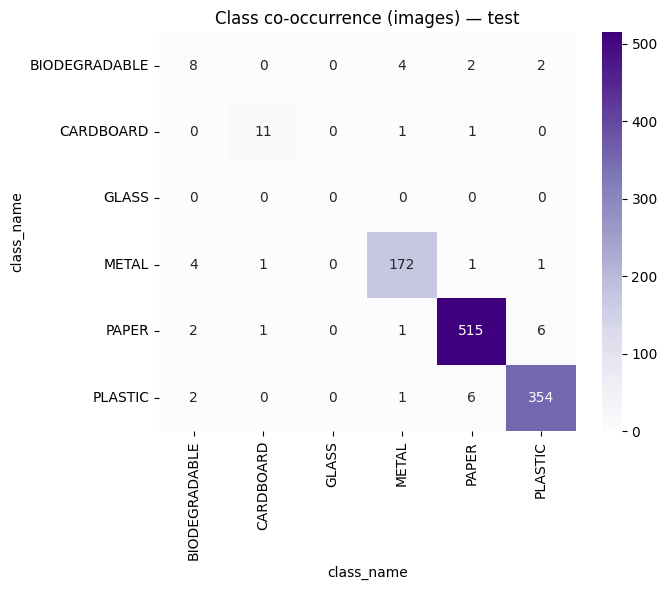

In [ ]:
organic_ids=[i for i,name in NAMES.items() if 'BIODEGRAD' in name.upper() or 'ORGANIC' in name.upper()]
organic_id=organic_ids[0] if organic_ids else None
if organic_id is None: print('No organic class found. Check class names.')
else:
    ob=boxes_df[boxes_df.class_id==organic_id]
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for ax,split in zip(axes,split_order):
        b=ob[ob.split==split]
        if len(b):
            h,xe,ye=np.histogram2d(b.y,b.x,bins=12,range=[[0,1],[0,1]])
            sns.heatmap(h,ax=ax,cmap='magma',cbar=True)
        ax.set_title(f'Organic center locations: {split} (n={len(b)})');ax.set_xlabel('x bins');ax.set_ylabel('y bins')
    plt.tight_layout();plt.savefig(OUTPUT/'organic_location_heatmap.png',dpi=160);plt.show()

presence=boxes_df.groupby(['split','image','class_name']).size().unstack(fill_value=0).gt(0)
if len(presence):
    for split in split_order:
        sub=presence.loc[split] if split in presence.index.get_level_values(0) else pd.DataFrame(columns=presence.columns)
        mat=sub.astype(int).T.dot(sub.astype(int))
        plt.figure(figsize=(7,6));sns.heatmap(mat,annot=True,fmt='d',cmap='Purples');plt.title(f'Class co-occurrence (images) — {split}')
        plt.tight_layout();plt.savefig(OUTPUT/f'cooccurrence_{split}.png',dpi=160);plt.show()


## 7 · Exact duplicates across splits (potential leakage)

In [ ]:
# SHA-256 on file bytes; can take several minutes on Google Drive.
sha_rows=[]
for row in tqdm(images_df.itertuples(index=False),total=len(images_df),desc='Hashing images'):
    try:
        h=hashlib.sha256()
        with open(row.image,'rb') as f:
            for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
        sha_rows.append({'split':row.split,'image':row.image,'sha256':h.hexdigest()})
    except Exception as e: issues.append({'split':row.split,'image':row.image,'issue':'hash_error','details':str(e)})
sha_df=pd.DataFrame(sha_rows)
sha_df.to_csv(OUTPUT/'image_hashes.csv',index=False)
dups=sha_df.groupby('sha256').filter(lambda g:g['split'].nunique()>1).sort_values('sha256') if len(sha_df) else sha_df
dups.to_csv(OUTPUT/'cross_split_exact_duplicates.csv',index=False)
print('Exact duplicate image files appearing in multiple splits:',dups.sha256.nunique() if len(dups) else 0)
display(dups.head(30))
print('Note: exact hashing does not detect resized or near-duplicate images.')


Hashing images:   0%|          | 0/10464 [00:00<?, ?it/s]

Exact duplicate image files appearing in multiple splits: 0


""


Note: exact hashing does not detect resized or near-duplicate images.


## 8 · Inspect all organic TEST images with ground-truth boxes

Organic TEST images: 8; annotated organic objects: 49


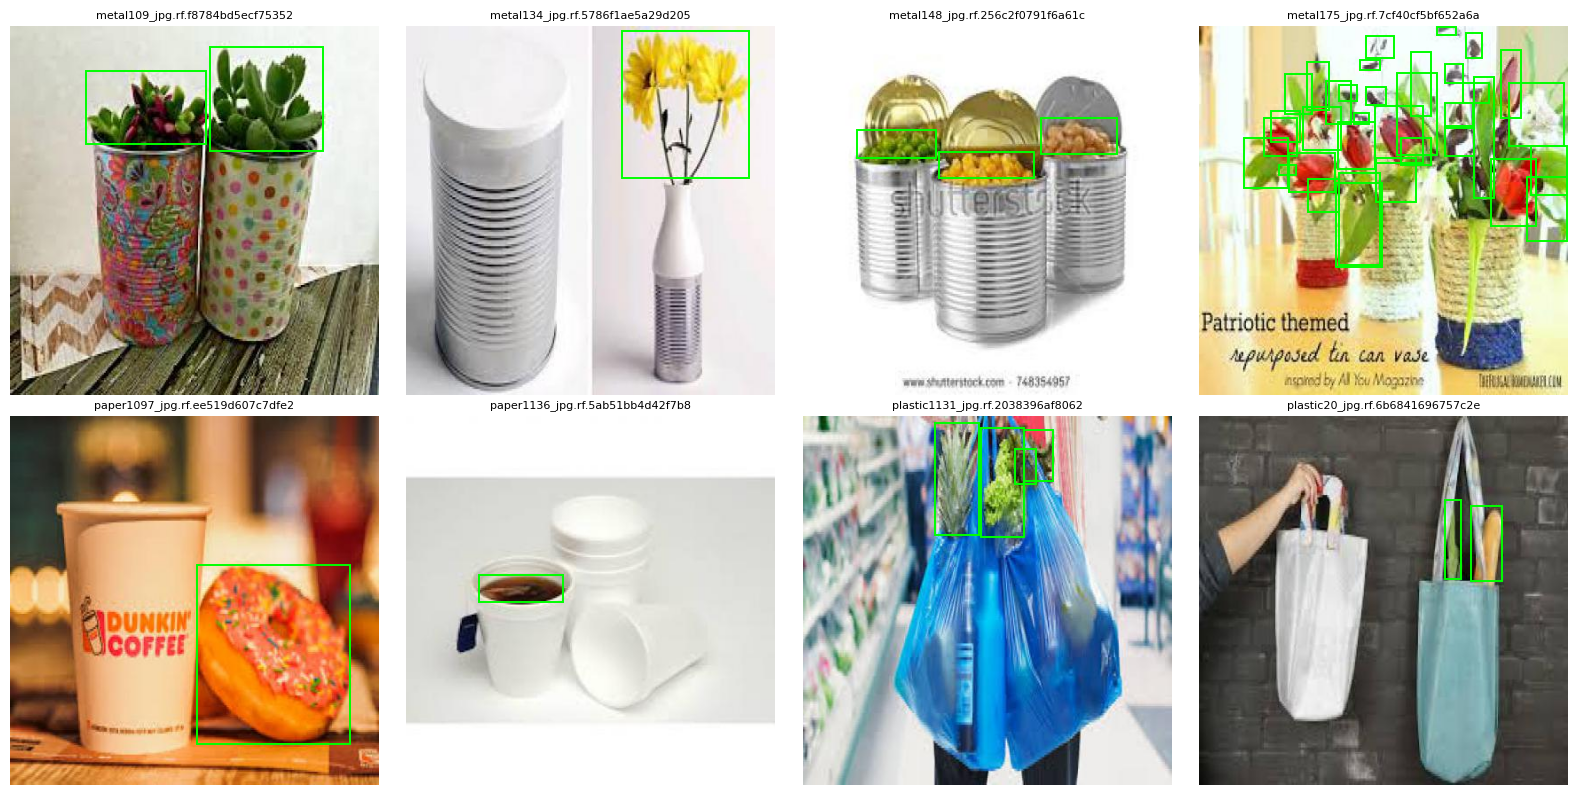

In [ ]:
if organic_id is not None:
    organic_test=boxes_df[(boxes_df.split=='test')&(boxes_df.class_id==organic_id)]
    paths=organic_test.image.drop_duplicates().tolist()
    print(f'Organic TEST images: {len(paths)}; annotated organic objects: {len(organic_test)}')
    if not paths: print('No organic test examples available.')
    for start in range(0,len(paths),8):
        subset=paths[start:start+8]
        fig,axes=plt.subplots((len(subset)+3)//4,4,figsize=(16,4*((len(subset)+3)//4)))
        axes=np.array(axes).reshape(-1)
        for ax,img_path in zip(axes,subset):
            with Image.open(img_path) as im: im=ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(im)
            for b in organic_test[organic_test.image==img_path].itertuples():
                x0=(b.x-b.w/2)*im.width; y0=(b.y-b.h/2)*im.height
                ax.add_patch(plt.Rectangle((x0,y0),b.w*im.width,b.h*im.height,fill=False,edgecolor='lime',linewidth=1.4))
            ax.set_title(Path(img_path).name[:32],fontsize=8);ax.axis('off')
        for ax in axes[len(subset):]:ax.axis('off')
        plt.tight_layout();plt.savefig(OUTPUT/f'organic_test_examples_{start//8+1}.png',dpi=150);plt.show()


##Inspect all classes TEST images with ground-truth boxes


BIODEGRADABLE TEST images: 8; annotated BIODEGRADABLE objects: 49


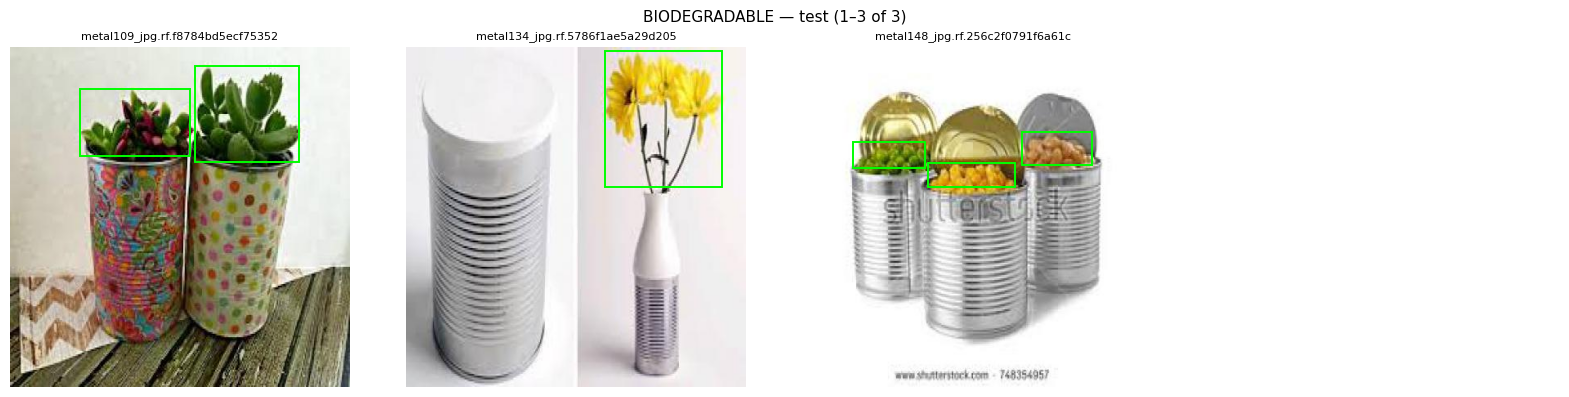


CARDBOARD TEST images: 11; annotated CARDBOARD objects: 20


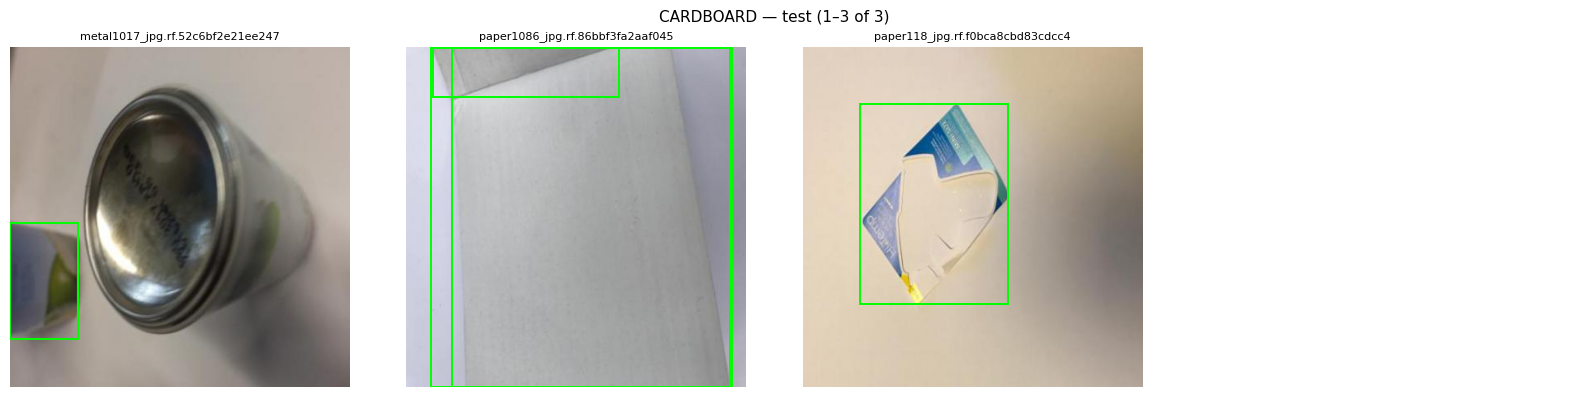


GLASS TEST images: 0; annotated GLASS objects: 0
No GLASS test examples available.

METAL TEST images: 172; annotated METAL objects: 533


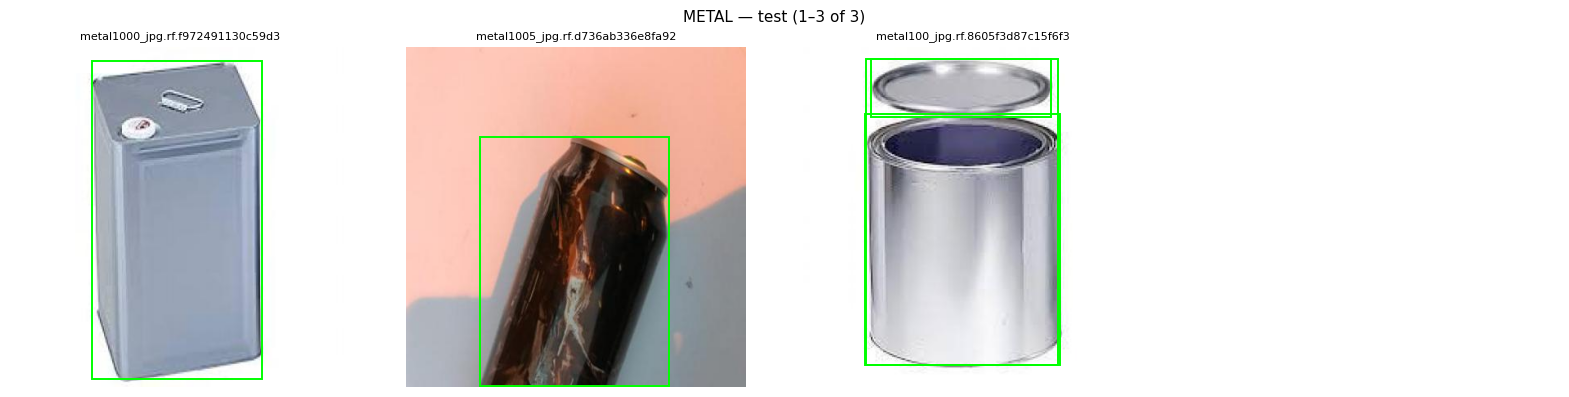


PAPER TEST images: 515; annotated PAPER objects: 1375


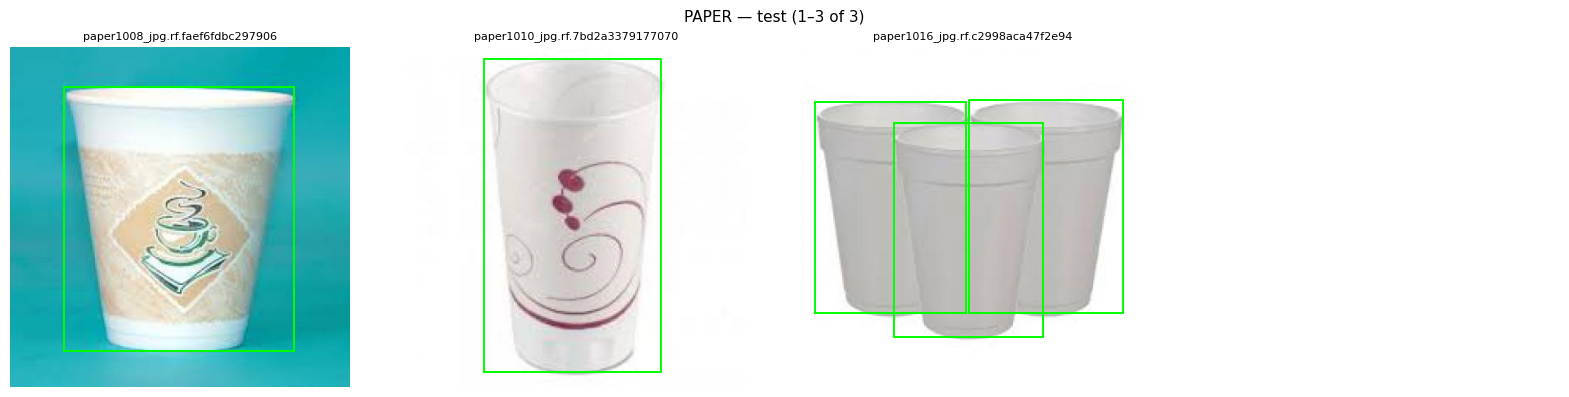


PLASTIC TEST images: 354; annotated PLASTIC objects: 1585


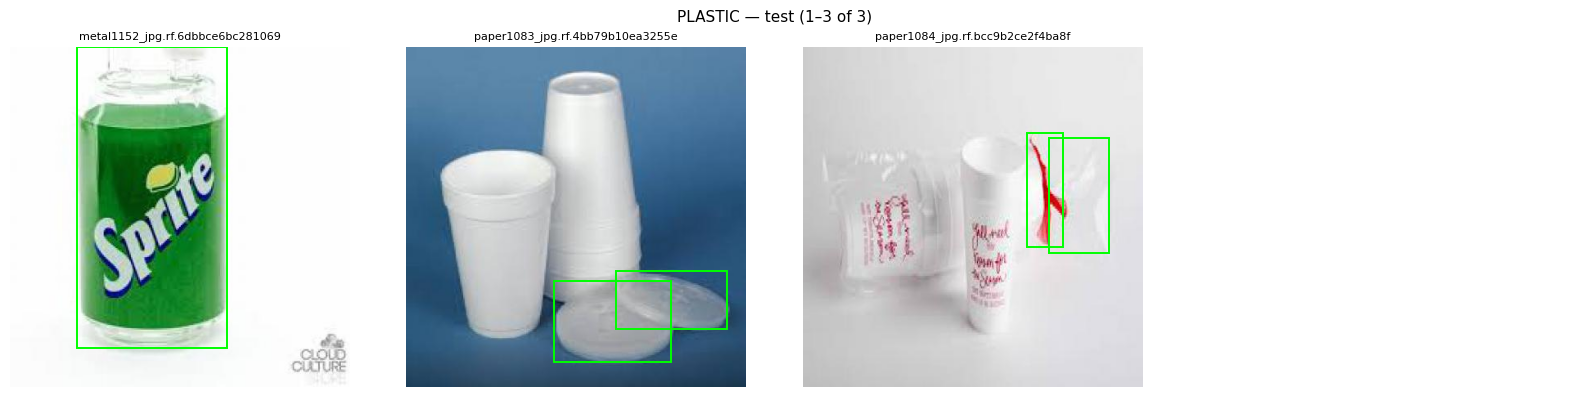

In [ ]:
SPLIT = 'test'
MAX_PER_CLASS = 3  # None = all images (same as original); set e.g. 8 to show only the first 8 per class

for cid in sorted(NAMES):
    cname = NAMES[cid]
    cls_boxes = boxes_df[(boxes_df.split == SPLIT) & (boxes_df.class_id == cid)]
    paths = cls_boxes.image.drop_duplicates().tolist()
    print(f'\n{cname} {SPLIT.upper()} images: {len(paths)}; annotated {cname} objects: {len(cls_boxes)}')
    if not paths:
        print(f'No {cname} {SPLIT} examples available.')
        continue
    if MAX_PER_CLASS:
        paths = paths[:MAX_PER_CLASS]
    for start in range(0, len(paths), 8):
        subset = paths[start:start + 8]
        fig, axes = plt.subplots((len(subset) + 3) // 4, 4, figsize=(16, 4 * ((len(subset) + 3) // 4)))
        axes = np.array(axes).reshape(-1)
        for ax, img_path in zip(axes, subset):
            with Image.open(img_path) as im: im = ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(im)
            for b in cls_boxes[cls_boxes.image == img_path].itertuples():
                x0 = (b.x - b.w / 2) * im.width; y0 = (b.y - b.h / 2) * im.height
                ax.add_patch(plt.Rectangle((x0, y0), b.w * im.width, b.h * im.height, fill=False, edgecolor='lime', linewidth=1.4))
            ax.set_title(Path(img_path).name[:32], fontsize=8); ax.axis('off')
        for ax in axes[len(subset):]: ax.axis('off')
        fig.suptitle(f'{cname} — {SPLIT} ({start + 1}–{start + len(subset)} of {len(paths)})', fontsize=11)
        plt.tight_layout()
        plt.savefig(OUTPUT / f'{cname.lower()}_{SPLIT}_examples_{start // 8 + 1}.png', dpi=150)
        plt.show()

## 9 · Final audit summary and research-relevant warnings

In [ ]:
lines=['='*70,'FINAL DATASET EDA SUMMARY','='*70,f'Dataset: {DATASET_ROOT}',f'Class mapping: {NAMES}','']
for split in split_order:
    im=images_df[images_df.split==split];b=boxes_df[boxes_df.split==split]
    lines += [f'[{split.upper()}] images={len(im):,}, valid_boxes={len(b):,}, missing_label_files={(~im.label_exists).sum():,}, empty_or_no_valid_boxes={(im.n_valid_objects==0).sum():,}, invalid_annotation_rows={im.invalid_rows.sum():,}']
    for cid,name in NAMES.items():
        sub=b[b.class_id==cid]
        lines.append(f'  {name}: boxes={len(sub):,}, images={sub.image.nunique():,}, share={(100*len(sub)/len(b)) if len(b) else 0:.2f}%')
    lines.append('')
lines.append(f'Exact cross-split duplicate files: {dups.sha256.nunique() if len(dups) else 0}')
if organic_id is not None:
    v=counts.loc[NAMES[organic_id],'val']; t=counts.loc[NAMES[organic_id],'test']
    lines.append(f'ORGANIC validation/test object counts: {v:,} / {t:,} (ratio={v/t:.1f}x)' if t else 'ORGANIC has zero TEST objects!')
for cid,name in NAMES.items():
    if counts.loc[name,'test']==0:lines.append(f'WARNING: {name} has ZERO annotated objects in TEST; its test AP cannot be estimated.')
lines += ['', 'IMPORTANT: This notebook audits dataset distributions and label structure; it cannot prove why a model failed.', 'Do not re-split and evaluate an already-trained model on previously seen training images.', 'Missing label files can mean intentional background images OR an annotation problem; review manually.', 'Image-level class counts and box-level counts are different; both are reported.', '='*70]
report='\n'.join(lines)
print(report)
(OUTPUT/'FINAL_EDA_SUMMARY.txt').write_text(report)
print('\nSaved CSVs, charts, examples and final report to:',OUTPUT)


FINAL DATASET EDA SUMMARY
Dataset: /content/garbage
Class mapping: {0: 'BIODEGRADABLE', 1: 'CARDBOARD', 2: 'GLASS', 3: 'METAL', 4: 'PAPER', 5: 'PLASTIC'}

[TRAIN] images=7,324, valid_boxes=51,601, missing_label_files=0, empty_or_no_valid_boxes=0, invalid_annotation_rows=0
  BIODEGRADABLE: boxes=31,714, images=1,603, share=61.46%
  CARDBOARD: boxes=3,385, images=1,053, share=6.56%
  GLASS: boxes=5,429, images=1,879, share=10.52%
  METAL: boxes=3,948, images=1,328, share=7.65%
  PAPER: boxes=2,979, images=1,238, share=5.77%
  PLASTIC: boxes=4,146, images=1,019, share=8.03%

[VAL] images=2,098, valid_boxes=18,910, missing_label_files=0, empty_or_no_valid_boxes=0, invalid_annotation_rows=0
  BIODEGRADABLE: boxes=13,632, images=676, share=72.09%
  CARDBOARD: boxes=1,291, images=438, share=6.83%
  GLASS: boxes=2,380, images=805, share=12.59%
  METAL: boxes=1,360, images=398, share=7.19%
  PAPER: boxes=33, images=15, share=0.17%
  PLASTIC: boxes=214, images=91, share=1.13%

[TEST] images=1,04